# ДЗ 1

## Бэггинг и бустинг
Для датасета creditcardfraud (мошенничество с кредитными картами, 0 - нет мошенничества, 1 - есть)
- подобрать параметры с помощью GridSearchCV
- вывести и выбрать наилучшие
- обучить бэггинг и бустинг
- сравнить модели (вывести информацию по метрикам)

Для выполнения можно воспользоваться кодом с семинара. Код для загрузки датасета ниже:

# Import Libraries

In [ ]:
import gdown

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline

# Models
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# Metrics
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, classification_report, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

## Load Dataset

In [ ]:
file_id = '1Jzlvck0AgfLXTR60t_cpQM-FrJY5j3qI'
output_file = 'creditcard.csv'

# gdown автоматически обрабатывает страницу подтверждения для больших файлов
gdown.download(id=file_id, output=output_file, quiet=False)

# Теперь читаем локальный файл
df = pd.read_csv(output_file)
df.head()

Downloading...
From (original): https://drive.google.com/uc?id=1Jzlvck0AgfLXTR60t_cpQM-FrJY5j3qI
From (redirected): https://drive.google.com/uc?id=1Jzlvck0AgfLXTR60t_cpQM-FrJY5j3qI&confirm=t&uuid=352c8860-677e-4d87-add2-b8265622b33d
To: /content/creditcard.csv
100%|██████████| 151M/151M [00:01<00:00, 127MB/s]


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Dataset Overview

In [ ]:
print('--- Dataset: creditcard ---')
print(df.info())
print('Describe Info:\n')
display(df.describe().T)
print('Missing values\n')
display(df.isna().sum())
print(f'Number of duplicated rows: {df.duplicated().sum()}')

--- Dataset: creditcard ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-n

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


Missing values



,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Number of duplicated rows: 1081


In [ ]:
duplicated_idx_list = df[df.duplicated() == True].index.tolist()
df = df.drop(index=duplicated_idx_list)

print(f'Number of duplicated rows: {df.duplicated().sum()}')

Number of duplicated rows: 0


In [ ]:
df['Class'].value_counts(normalize=True)

,proportion
Class,
0,0.998333
1,0.001667


## Features and Target

In [ ]:
X = df.iloc[:, :-1]
y = df['Class']

## Test / Train split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 15, stratify=y)

print(f'X_train shape: {X_train.shape[0]} \nX_test shape: {X_test.shape[0]}')

X_train shape: 226980 
X_test shape: 56746


## Random Forest GridSearch

In [ ]:
# Задаем сетку параметров
param_grid_rf = {
    'clf__n_estimators': [50, 150],       # Число деревьев
    'clf__max_depth': [None, 5, 10],           # Глубина
    'clf__min_samples_leaf': [1, 2, 4]         # Мин. объектов в листе
}
# Пайплайн
pipe_rf = Pipeline([
    ('clf', RandomForestClassifier(class_weight='balanced', random_state=15))
])

# CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# GridSearchCV
grid_search = GridSearchCV(
    pipe_rf, param_grid_rf, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=1
)

grid_search.fit(X_train, y_train)

print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучший ROC-AUC на CV: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Лучшие параметры: {'clf__max_depth': 10, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 150}
Лучший ROC-AUC на CV: 0.9841


## HistGradientBoosting GridSearch

In [ ]:
# Задаем сетку параметров
param_grid_hgb = {
    'clf__max_iter': [100, 200, 300],
    'clf__max_depth': [None, 5, 10],
    'clf__learning_rate': [0.01, 0.1, 0.2],
    'clf__l2_regularization': [0.0, 0.1, 0.5]
}

# Пайплайн
pipe_hgb = Pipeline([('clf', HistGradientBoostingClassifier(random_state=15))])

grid_hgb = GridSearchCV(pipe_hgb, param_grid_hgb, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=1)
grid_hgb.fit(X_train, y_train)
print(f"HGB Лучший ROC-AUC: {grid_hgb.best_score_:.4f}")
print(f"HGB Лучшие параметры: {grid_hgb.best_params_}")

Fitting 5 folds for each of 81 candidates, totalling 405 fits
HGB Лучший ROC-AUC: 0.9831
HGB Лучшие параметры: {'clf__l2_regularization': 0.1, 'clf__learning_rate': 0.01, 'clf__max_depth': 10, 'clf__max_iter': 300}


### Model Results for Random Forest

--- Метрики для Random Forest ---
Accuracy: 0.9993
F1-score: 0.7910
Classification repot:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.85      0.74      0.79        95

    accuracy                           1.00     56746
   macro avg       0.93      0.87      0.90     56746
weighted avg       1.00      1.00      1.00     56746



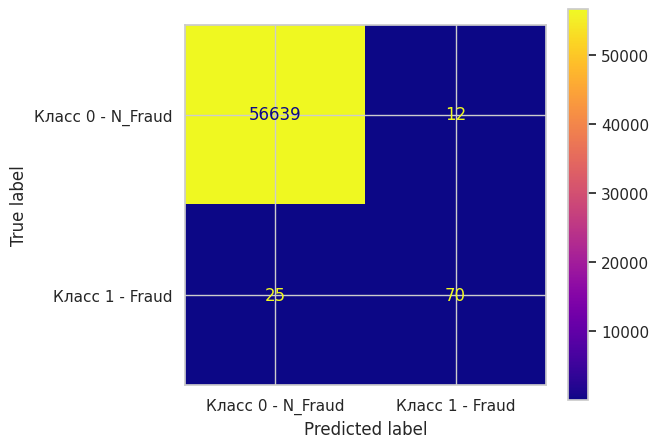

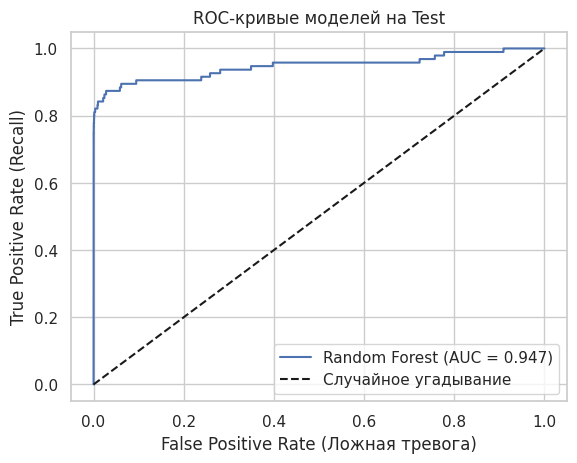

In [ ]:
def evaluate_model(model, X_test, y_test, model_name):

  # Prediction

  y_pred = model.predict(X_test)
  y_proba = model.predict_proba(X_test)[:, 1] # Вероятность для класса 1 (Мошенничество)

  # Metrics

  print(f'--- Метрики для {model_name} ---')
  print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
  print(f'F1-score: {f1_score(y_test, y_pred):.4f}')

  print('Classification report:\n', classification_report(y_test, y_pred))

  # Matrix map

  cm = confusion_matrix(y_test, y_pred)
  disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Класс 0 - N_Fraud', 'Класс 1 - Fraud'])
  disp.plot(cmap=plt.cm.plasma)
  plt.tight_layout()
  plt.show()

  # Roc-Auc figure

  fpr, tpr, _ = roc_curve(y_test, y_proba)
  auc = roc_auc_score(y_test, y_proba)

  plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc:.3f})")
  plt.plot([0, 1], [0, 1], 'k--', label="Случайное угадывание")
  plt.xlabel("False Positive Rate (Ложная тревога)")
  plt.ylabel("True Positive Rate (Recall)")
  plt.title("ROC-кривые моделей на Test")
  plt.legend(loc="lower right")
  plt.show()

evaluate_model(grid_search.best_estimator_, X_test, y_test, "Random Forest")



### Model Results for HistGradientBoosting

--- Метрики для HistGradientBoosting ---
Accuracy: 0.9994
F1-score: 0.8095
Classification repot:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.93      0.72      0.81        95

    accuracy                           1.00     56746
   macro avg       0.97      0.86      0.90     56746
weighted avg       1.00      1.00      1.00     56746



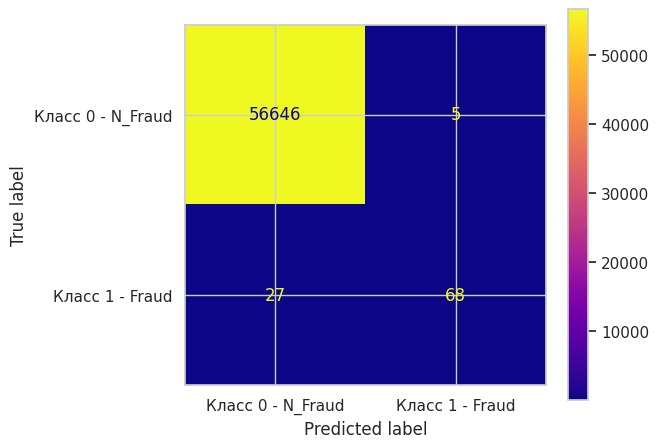

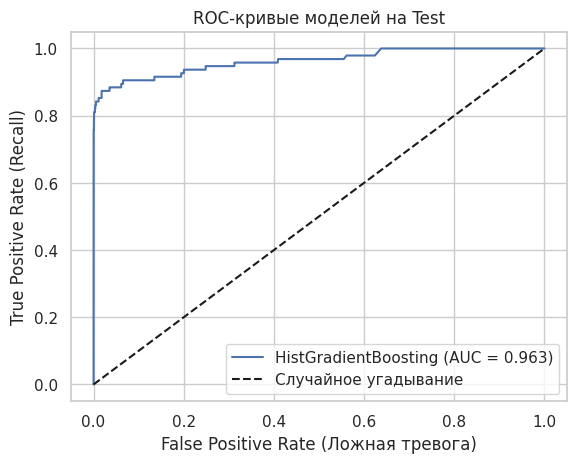

In [ ]:
evaluate_model(grid_hgb.best_estimator_, X_test, y_test, "HistGradientBoosting")

### Важность признаков (Feature Importance)

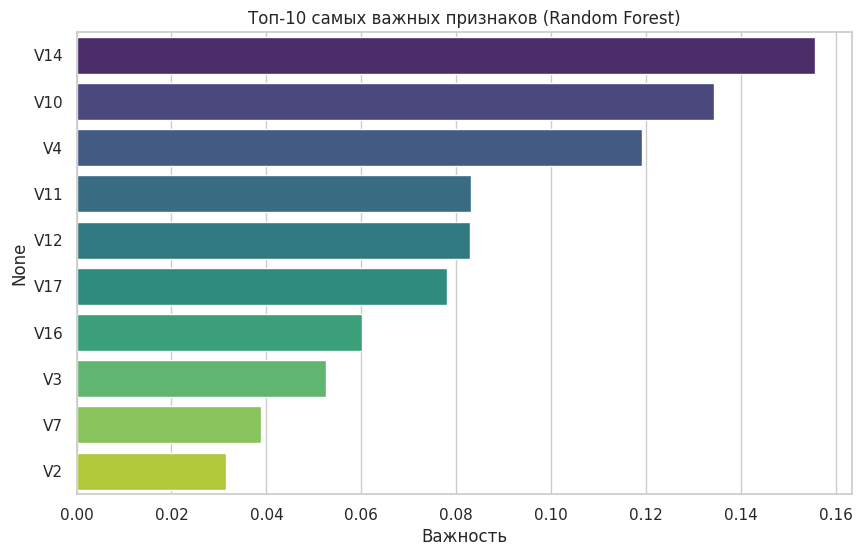

In [ ]:
model_rf = grid_search.best_estimator_.named_steps['clf']

# Создаем DataFrame с важностями
importances = pd.Series(model_rf.feature_importances_, index=X.columns)
top_10 = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_10.values, y=top_10.index, palette="viridis")
plt.title("Топ-10 самых важных признаков (Random Forest)")
plt.xlabel("Важность")
plt.show()

### Вывод

Для обеих моделей был проведен подбор гиперпараметров с помощью GridSearchCV

- Лучшие параметры для Random Forest: max_depth=10, min_samples_leaf=1, n_estimators=150 (ROC-AUC на CV = 0.9841).
- Лучшие параметры для HistGradientBoosting: l2_regularization=0.1, learning_rate=0.01, max_depth=10, max_iter=300 (ROC-AUC на CV = 0.9831).

- Сравнение Метрик:

Random Forest
> - Accuracy: 0.9993
> - F1-score: 0.7910
> - Roc_Auc: 0.947

HistGradientBoosting
> - Accuracy: 0.9994
> - F1-score: 0.8095
> - ROC-AUC: 0.963

По метрикам выигрывает модель HistGradientBoosting
Обе модели показали высокое качество разделения классов.


### Улучшения

#### Снизить порог для модели HistGradientBoosting


In [ ]:
model = grid_hgb.best_estimator_

y_probs_class1 = model.predict_proba(X_test)[:, 1]

# Стандартный порог 0.5
y_pred_default = (y_probs_class1 > 0.5).astype(int)

# Новый порог 0.3
y_pred_lowered = (y_probs_class1 > 0.3).astype(int)

print("=== СТАНДАРТНЫЙ ПОРОГ (0.5) ===")
print(classification_report(y_test, y_pred_default, target_names=['Класс 0 - N_Fraud', 'Класс 1 - Fraud']))


print("\n=== ПОНИЖЕННЫЙ ПОРОГ (0.3) ===")
print(classification_report(y_test, y_pred_lowered, target_names=['Класс 0 - N_Fraud', 'Класс 1 - Fraud']))


=== СТАНДАРТНЫЙ ПОРОГ (0.5) ===
                   precision    recall  f1-score   support

Класс 0 - N_Fraud       1.00      1.00      1.00     56651
  Класс 1 - Fraud       0.93      0.72      0.81        95

         accuracy                           1.00     56746
        macro avg       0.97      0.86      0.90     56746
     weighted avg       1.00      1.00      1.00     56746


=== ПОНИЖЕННЫЙ ПОРОГ (0.3) ===
                   precision    recall  f1-score   support

Класс 0 - N_Fraud       1.00      1.00      1.00     56651
  Класс 1 - Fraud       0.93      0.73      0.82        95

         accuracy                           1.00     56746
        macro avg       0.97      0.86      0.91     56746
     weighted avg       1.00      1.00      1.00     56746

